In [1]:
# ============================================================
# LOGISTIC REGRESSION
# Student Pass/Fail Prediction
# ============================================================

# ------------------------------------------------------------
# 1. Import Libraries
# ------------------------------------------------------------

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)


In [2]:
# ============================================================
# 2. Load Dataset
# ============================================================

data = pd.read_csv("student_logistic_regression.csv")

print("Original Dataset")
print(data.head())

print("\nDataset Shape:")
print(data.shape)


Original Dataset
   Student Name  Study Hours  Total Marks  Result
0  Aarav Sharma            5           72       1
1  Ananya Reddy            7           88       1
2   Arjun Kumar            3           38       0
3    Diya Patel            6           81       1
4   Rohan Singh            4           55       1

Dataset Shape:
(30, 4)


In [4]:
# ============================================================
# 3. DATA PREPROCESSING
# ============================================================

# ------------------------------------------------------------
# Check column names
# ------------------------------------------------------------

print("\nColumn Names:")
print(data.columns)


# ------------------------------------------------------------
# Remove extra spaces from column names
# ------------------------------------------------------------

data.columns = data.columns.str.strip()


# ------------------------------------------------------------
# Remove extra spaces from Student Name
# ------------------------------------------------------------

data["Student Name"] = data["Student Name"].str.strip()


# ------------------------------------------------------------
# Check missing values
# ------------------------------------------------------------

print("\nMissing Values:")
print(data.isnull().sum())


# ------------------------------------------------------------
# Remove missing values
# ------------------------------------------------------------

data = data.dropna()


# ------------------------------------------------------------
# Remove duplicate records
# ------------------------------------------------------------

data = data.drop_duplicates()


# ------------------------------------------------------------
# Convert numerical columns to numeric
# ------------------------------------------------------------

data["Study Hours"] = pd.to_numeric(
    data["Study Hours"],
    errors="coerce"
)

data["Total Marks"] = pd.to_numeric(
    data["Total Marks"],
    errors="coerce"
)

data["Result"] = pd.to_numeric(
    data["Result"],
    errors="coerce"
)


# ------------------------------------------------------------
# Remove rows with invalid numerical values
# ------------------------------------------------------------

data = data.dropna(
    subset=[
        "Study Hours",
        "Total Marks",
        "Result"
    ]
)


# ------------------------------------------------------------
# Check valid ranges
# ------------------------------------------------------------

data = data[
    (data["Study Hours"] >= 0) &
    (data["Total Marks"] >= 0) &
    (data["Total Marks"] <= 100)
]


print("\nCleaned Dataset:")
print(data.head())

print("\nCleaned Dataset Shape:")
print(data.shape)





Column Names:
Index(['Student Name', 'Study Hours', 'Total Marks', 'Result'], dtype='object')

Missing Values:
Student Name    0
Study Hours     0
Total Marks     0
Result          0
dtype: int64

Cleaned Dataset:
   Student Name  Study Hours  Total Marks  Result
0  Aarav Sharma            5           72       1
1  Ananya Reddy            7           88       1
2   Arjun Kumar            3           38       0
3    Diya Patel            6           81       1
4   Rohan Singh            4           55       1

Cleaned Dataset Shape:
(30, 4)


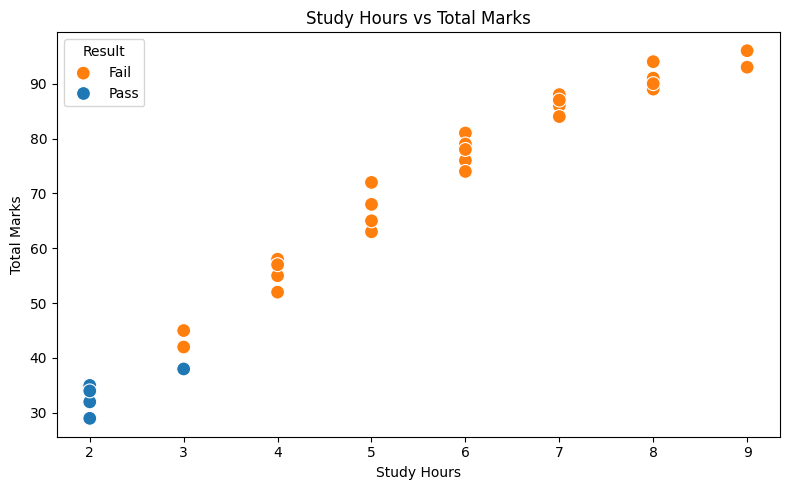

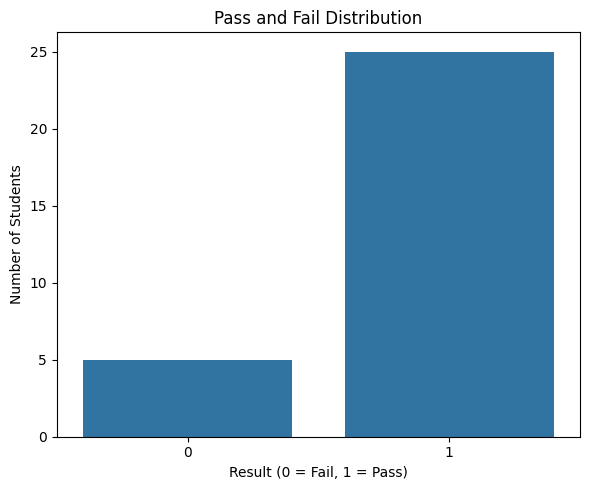

In [5]:
# ============================================================
# 4. DATA VISUALIZATION
# ============================================================


# ------------------------------------------------------------
# Visualization 1: Study Hours vs Total Marks
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=data,
    x="Study Hours",
    y="Total Marks",
    hue="Result",
    s=100
)

plt.title("Study Hours vs Total Marks")
plt.xlabel("Study Hours")
plt.ylabel("Total Marks")

plt.legend(
    title="Result",
    labels=["Fail", "Pass"]
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Visualization 2: Result Distribution
# ------------------------------------------------------------

plt.figure(figsize=(6, 5))

sns.countplot(
    data=data,
    x="Result"
)

plt.title("Pass and Fail Distribution")
plt.xlabel("Result (0 = Fail, 1 = Pass)")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()




In [6]:
# ============================================================
# 5. DEFINE INDEPENDENT AND DEPENDENT VARIABLES
# ============================================================

# Independent Variables
X = data[
    ["Study Hours", "Total Marks"]
]

# Dependent Variable
y = data["Result"]


# ============================================================
# 6. SPLIT DATASET
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


print("\nTraining Data Size:")
print(X_train.shape)

print("\nTesting Data Size:")
print(X_test.shape)


# ============================================================
# 7. FEATURE SCALING
# ============================================================

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)




Training Data Size:
(22, 2)

Testing Data Size:
(8, 2)



Actual	Predicted
0 	 0
1 	 1
1 	 1
1 	 1
1 	 1
1 	 1
1 	 1
1 	 1

Accuracy Score:
1.0

Confusion Matrix:
[[1 0]
 [0 7]]


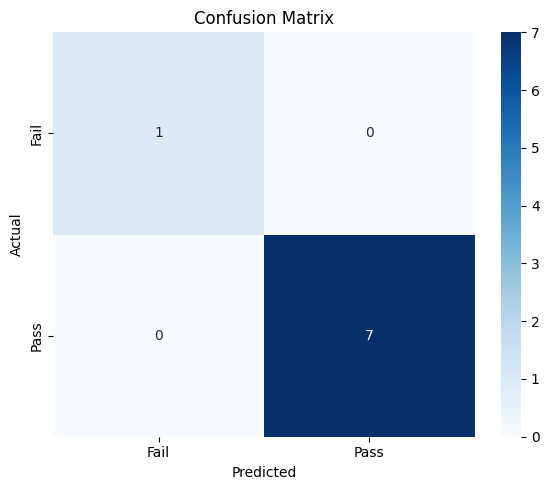


Classification Report:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         1
        Pass       1.00      1.00      1.00         7

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8


Model Coefficients:
Study Hours: 0.9997389097878223
Total Marks: 1.2506040258418702

Model Intercept: 2.8207356254445375


In [7]:

# ============================================================
# 8. TRAIN LOGISTIC REGRESSION MODEL
# ============================================================

model = LogisticRegression(
    random_state=42
)

model.fit(
    X_train,
    y_train
)


# ============================================================
# 9. PREDICTION
# ============================================================

y_pred = model.predict(X_test)


# ============================================================
# 10. DISPLAY ACTUAL AND PREDICTED VALUES
# ============================================================

print("\nActual\tPredicted")

for actual, predicted in zip(
    y_test,
    y_pred
):

    print(
        actual,
        "\t",
        predicted
    )


# ============================================================
# 11. ACCURACY
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("\nAccuracy Score:")
print(accuracy)


# ============================================================
# 12. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)


# ============================================================
# 13. CONFUSION MATRIX VISUALIZATION
# ============================================================

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.tight_layout()
plt.show()


# ============================================================
# 14. CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Fail", "Pass"]
    )
)


# ============================================================
# 15. MODEL COEFFICIENTS
# ============================================================

print("\nModel Coefficients:")

print(
    "Study Hours:",
    model.coef_[0][0]
)

print(
    "Total Marks:",
    model.coef_[0][1]
)

print(
    "\nModel Intercept:",
    model.intercept_[0]
)